# Assignment 1 – EDA & Baseline

**Group 57** – Berke Vural (23118080755)

Competition: [MITSUI&CO. Commodity Prediction Challenge](https://www.kaggle.com/competitions/mitsui-commodity-prediction-challenge)

## 1. Problem Definition

**Task.** We predict future returns of financial instruments related to commodities.
The data are daily prices from four markets. These are LME (metals), JPX (Japanese
futures), US stocks and Forex (exchange rates).

**Target.** `train_labels.csv` has 424 target columns (`target_0` ... `target_423`).
4 of them are the log return of one instrument. The other 420 are the log return of
instrument A minus the log return of instrument B.

The return is measured over `lag` days, where `lag` is 1, 2, 3 or 4.
For a single instrument the target on day `t` is

`target(t) = log(price[t + lag + 1] / price[t + 1])`

`target_pairs.csv` shows the instrument(s) and the lag of each target.
This is a regression problem with 424 outputs.

**Metric.** For each day, the Spearman rank correlation between our 424 predictions
and the 424 true targets is computed. The final score is the mean of these daily
correlations divided by their standard deviation (a Sharpe-ratio-like score).
This means that only the order of the predictions within a day matters, not the
exact values. It also means that a model that is a little bit right every day is
better than a model that is very right on some days and wrong on others.

## 2. Data Overview

We load the data with the `load_data` function from `src/data.py`.

In [1]:
from src.data import load_data

train, labels, target_pairs = load_data()

print("train:       ", train.shape)
print("labels:      ", labels.shape)
print("target_pairs:", target_pairs.shape)

train:        (1961, 558)
labels:       (1961, 425)
target_pairs: (424, 3)


`train` has 1961 days. It has 557 price/volume columns plus `date_id`.
`labels` has the same 1961 days and 424 target columns plus `date_id`.
`target_pairs` has one row for each target.

557 columns is a lot for only 1961 days. This is important for the model, because
a model with too many inputs can easily overfit.

In [2]:
print(train.dtypes.value_counts())
print(labels.dtypes.value_counts())

float64    557
int64        1
Name: count, dtype: int64
float64    424
int64        1
Name: count, dtype: int64


All feature and target columns are numbers (`float64`). Only `date_id` is an integer.
There are no categorical columns, so we do not need any encoding.

In [3]:
markets = train.columns[1:].str.split("_").str[0]
markets.value_counts()

US     475
JPX     40
FX      38
LME      4
Name: count, dtype: int64

Most columns come from US stocks (475 of 557). JPX has 40 columns, Forex 38 and LME only 4.
So the data is not balanced between markets. The US stocks will have the biggest
effect on a model that uses all columns.

In [4]:
example_cols = ["LME_AH_Close", "JPX_Gold_Standard_Futures_Close",
                "US_Stock_VT_adj_close", "FX_USDJPY"]
train[example_cols].describe()

,LME_AH_Close,JPX_Gold_Standard_Futures_Close,US_Stock_VT_adj_close,FX_USDJPY
count,1910.000000,1845.000000,1894.000000,1961.000000
mean,2252.202853,7699.157182,86.056667,124.678585
std,398.544566,3067.132209,19.023997,18.301781
min,1462.000000,4174.000000,49.206300,102.678985
25%,1925.250000,5197.000000,66.942075,108.926003
50%,2245.500000,6621.000000,86.783800,113.564498
75%,2512.000000,8953.000000,97.722300,143.853034
max,3849.000000,16306.000000,132.681854,161.608501


The prices have very different scales. For example, JPX gold is around 7700,
LME aluminium around 2250 and the US stock VT around 86.
A model like linear regression is sensitive to scale, so we will scale the inputs.

The `count` row is smaller than 1961 for most columns (for example 1845 for JPX gold).
So there are missing values. We look at them in the next part.

In [5]:
labels[["target_0", "target_1", "target_106", "target_423"]].describe()

,target_0,target_1,target_106,target_423
count,1827.000000,1784.000000,1827.000000,1768.000000
mean,0.000470,-0.000575,0.000457,-0.003327
std,0.011925,0.016930,0.015297,0.053855
min,-0.123763,-0.120442,-0.164627,-0.212359
25%,-0.004567,-0.010452,-0.006850,-0.032805
50%,0.000928,-0.000954,0.001381,-0.002256
75%,0.006270,0.008901,0.008887,0.027942
max,0.087470,0.113968,0.115999,0.244952


The targets are small numbers with a mean close to 0. This is normal for daily returns.
The standard deviation is about 0.01–0.02 for lag 1, but 0.05 for `target_423` (lag 4),
because a return over 4 days changes more than a return over 1 day.
The min and max values (for example −0.12 and 0.09 for `target_0`) are far from the
quartiles, so the targets have some extreme values (outliers).

In [6]:
missing = train.drop(columns="date_id").isna().mean() * 100
missing.groupby(markets).mean().round(1)

FX     0.0
JPX    5.9
LME    2.6
US     4.3
dtype: float64

In [7]:
missing.sort_values(ascending=False).head(8)

US_Stock_GOLD_adj_open           87.353391
US_Stock_GOLD_adj_close          87.353391
US_Stock_GOLD_adj_volume         87.353391
US_Stock_GOLD_adj_low            87.353391
US_Stock_GOLD_adj_high           87.353391
JPX_Gold_Mini_Futures_Low         5.915349
JPX_Gold_Standard_Futures_Low     5.915349
JPX_Platinum_Mini_Futures_Low     5.915349
dtype: float64

Forex has no missing values. JPX (5.9 %), US (4.3 %) and LME (2.6 %) have a few.
They are missing on days when that exchange was closed (holidays and time zone
differences). For example, on 67 days all US columns are empty.

The five `US_Stock_GOLD_*` columns are 87 % empty. They only have values for the
first 259 days. They carry almost no information, so we will drop them.
The other missing values are few, so we will fill them in the preprocessing step.

In [8]:
target_missing = labels.drop(columns="date_id").isna().mean() * 100
print("Average missing % in targets:", round(target_missing.mean(), 1))
print("Max missing % in one target: ", round(target_missing.max(), 1))

Average missing % in targets: 10.5
Max missing % in one target:  18.9


The targets are missing 10.5 % of the time on average (up to 18.9 %). A target is
missing when one of its instruments did not trade. We must not fill the targets,
because that would mean inventing the answer. Missing targets are skipped when
we train and evaluate the model.

In [9]:
print("Duplicate rows:    ", train.duplicated().sum())
print("Duplicate date_ids:", train["date_id"].duplicated().sum())

Duplicate rows:     0
Duplicate date_ids: 0


There are no duplicate rows and every `date_id` appears only once.
So each row is one unique day and we do not need to remove anything.

## 3. Exploratory Data Analysis

### 3.1 Distribution of the targets

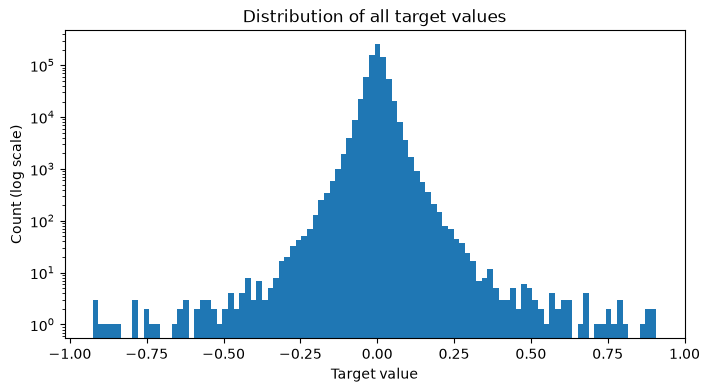

In [10]:
import matplotlib.pyplot as plt

all_targets = labels.drop(columns="date_id").stack()

plt.figure(figsize=(8, 4))
plt.hist(all_targets, bins=100)
plt.yscale("log")
plt.title("Distribution of all target values")
plt.xlabel("Target value")
plt.ylabel("Count (log scale)")
plt.show()

In [11]:
print("Skewness:", round(all_targets.skew(), 2))
print("Kurtosis:", round(all_targets.kurt(), 2))
print("Values between -0.05 and 0.05:", round((all_targets.abs() < 0.05).mean() * 100, 1), "%")

Skewness: 0.1
Kurtosis: 34.0
Values between -0.05 and 0.05: 82.0 %


The targets are centred around 0 and the distribution is almost symmetric (skewness 0.1).
82 % of the values are between −0.05 and 0.05. But the tails are very long and some
values reach ±0.9. The kurtosis is 34, much bigger than 0 for a normal distribution,
so there are many more extreme values than in a normal distribution.

The competition metric uses ranks (Spearman), so a few extreme values do not change
the score much. But a linear regression trained with squared error is sensitive to
extreme values, so these outliers can pull the model. We keep this in mind for the
baseline.

### 3.2 Spread of the targets by lag

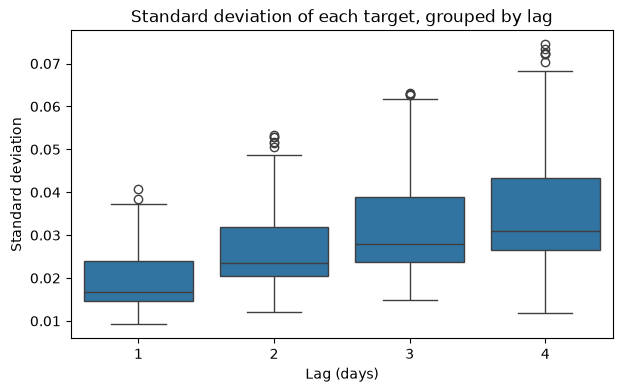

In [12]:
import seaborn as sns

std_by_lag = target_pairs.copy()
std_by_lag["std"] = labels.drop(columns="date_id").std().values

plt.figure(figsize=(7, 4))
sns.boxplot(data=std_by_lag, x="lag", y="std")
plt.title("Standard deviation of each target, grouped by lag")
plt.xlabel("Lag (days)")
plt.ylabel("Standard deviation")
plt.show()

The spread of the targets grows with the lag. The median standard deviation is about
0.017 for lag 1 and 0.031 for lag 4. This makes sense, because a return over 4 days can move
more than a return over 1 day.

Inside each lag, some targets are much more volatile than others (the points above
the boxes). The most volatile targets are lag 4 pairs of an LME or JPX metal with a US mining
or energy stock, with a standard deviation around 0.07.

Because the metric compares the 424 predictions of one day by rank, the model should
not simply predict bigger values for lag 4 targets. It has to get the order right.

### 3.3 Prices over time

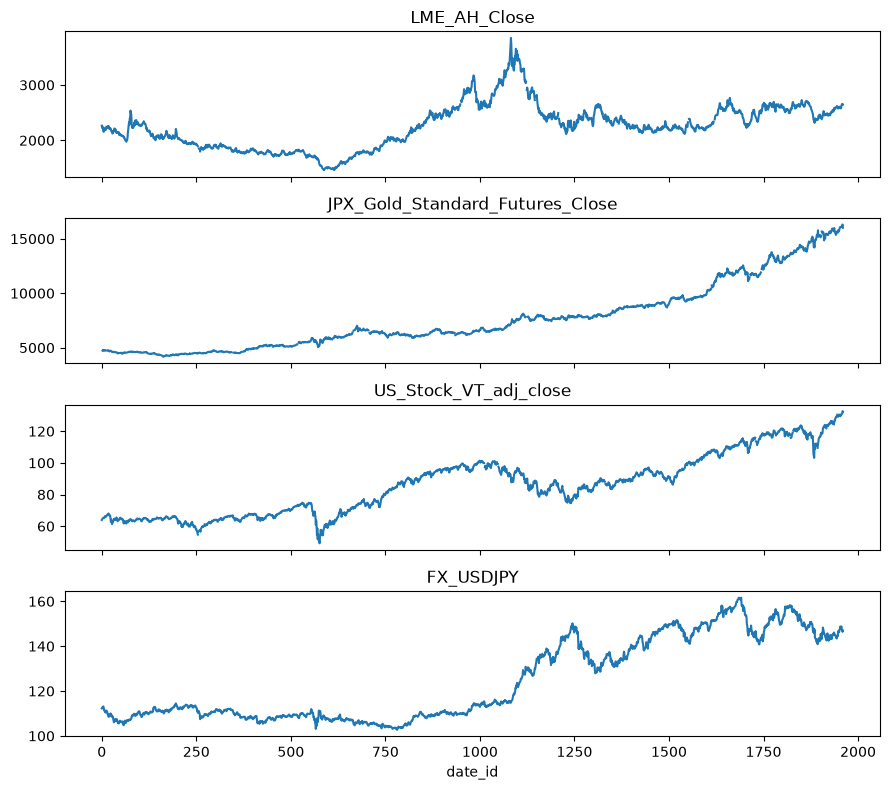

In [13]:
fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)

for ax, col in zip(axes, example_cols):
    ax.plot(train["date_id"], train[col])
    ax.set_title(col)

axes[-1].set_xlabel("date_id")
plt.tight_layout()
plt.show()

The prices do not stay around one level. They have long trends. JPX gold goes from
about 4700 to 16000 and the US stock VT doubles. There are also sudden events, for
example the sharp drop of VT around day 576 and the peak of LME aluminium around
day 1082.

Because of this, raw prices are not a good input for a model. A price level seen in
the future (for example gold at 16000) never appeared in the past. Returns (daily
price changes) are more stable, and the targets are also returns. So we will use
returns as features.

Days that are close in time are also similar to each other. If we split train and
validation randomly, the model would see days right next to the validation days and
the score would be too optimistic. So we will split by time and use the last part of
the data as validation.

### 3.4 Relationship between today's return and the target

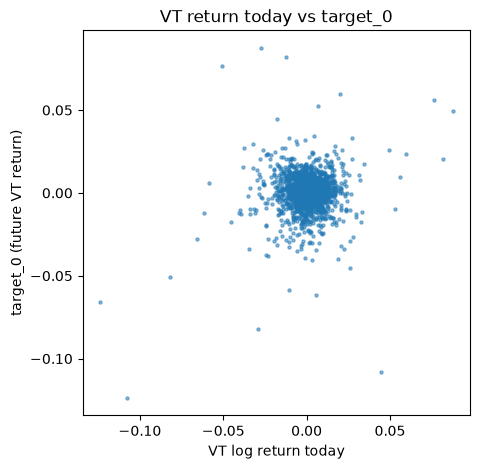

In [14]:
import numpy as np

vt_return = np.log(train["US_Stock_VT_adj_close"]).diff()

plt.figure(figsize=(5, 5))
plt.scatter(vt_return, labels["target_0"], s=5, alpha=0.5)
plt.title("VT return today vs target_0")
plt.xlabel("VT log return today")
plt.ylabel("target_0 (future VT return)")
plt.show()

In [15]:
small_days = vt_return.abs() < 0.03

print("Correlation (all days):  ", round(vt_return.corr(labels["target_0"]), 3))
print("Correlation (small days):", round(vt_return[small_days].corr(labels["target_0"][small_days]), 3))

Correlation (all days):   0.123
Correlation (small days): -0.025


Most points form a round cloud around 0, so today's return says very little about
the future return. The correlation is only 0.12. When we remove the days with a big
move (more than 3 %), the correlation drops to about 0. So the small relationship
comes from a few extreme days, for example the crash around day 576.

This is normal for financial data. Future returns are very hard to predict and any
signal is weak. We should not expect a high score from a simple model, and we must
be careful that the model does not learn only from a few extreme days.

### 3.5 Correlation between the targets

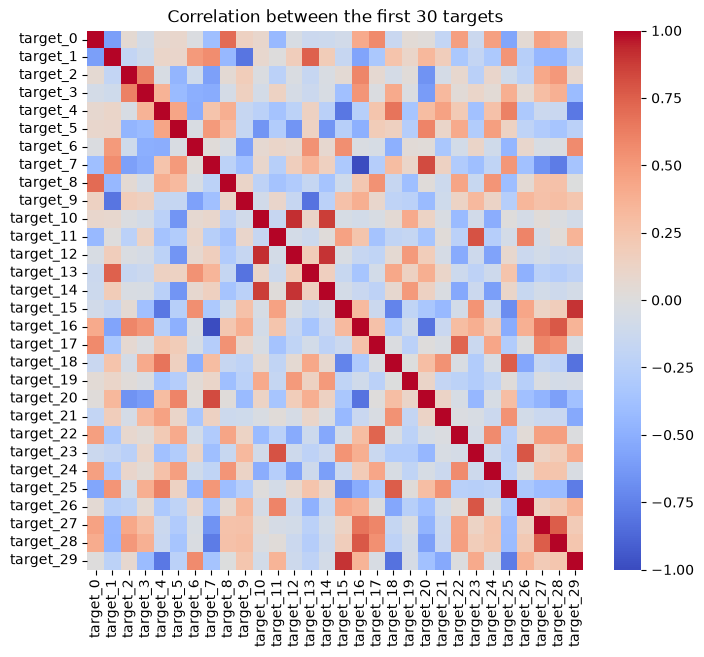

In [16]:
first_targets = labels.drop(columns="date_id").iloc[:, :30]

plt.figure(figsize=(8, 7))
sns.heatmap(first_targets.corr(), cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between the first 30 targets")
plt.show()

In [17]:
target_corr = labels.drop(columns="date_id").corr()

print(target_pairs.loc[[7, 10, 12, 14, 16]])
print("target_10 vs target_12:", round(target_corr.loc["target_10", "target_12"], 2))
print("target_7 vs target_16: ", round(target_corr.loc["target_7", "target_16"], 2))

       target  lag                                               pair
7    target_7    1              LME_ZS_Close - US_Stock_VYM_adj_close
10  target_10    1  JPX_Platinum_Standard_Futures_Close - US_Stock...
12  target_12    1    JPX_Platinum_Standard_Futures_Close - FX_CADCHF
14  target_14    1    JPX_Platinum_Standard_Futures_Close - FX_NZDJPY
16  target_16    1              US_Stock_VTV_adj_close - LME_ZS_Close
target_10 vs target_12: 0.92
target_7 vs target_16:  -1.0


Most targets are only weakly related, but some pairs are very strongly related.
`target_10`, `target_12` and `target_14` are all "JPX platinum minus something", and
their correlation is about 0.9. `target_7` (zinc minus VYM) and `target_16` (VTV minus
zinc) have a correlation of −1.0, because zinc is on the opposite side and VYM and VTV
are two very similar US funds.

So the 424 targets are not independent. Targets that share an instrument move
together. A model can use this, because what it learns for one instrument helps
for all targets that contain it.

## 4. Preprocessing

The preprocessing is in the `preprocess` function in `src/data.py`, so we can use the
same steps later in Assignment 2 and in the Kaggle submission.

First we keep only the closing prices (143 of 557 columns). All 424 targets are built
from closing prices, and fewer columns also lower the risk of overfitting. Then we drop
`US_Stock_GOLD_adj_close`, because it is 87 % empty.

Next we fill the missing prices with the last known price (forward fill). A missing
price means the exchange was closed, so the price did not change. Forward fill only
uses the past, so no future information goes into the data.

Then we turn the prices into daily log returns, `log(price today / price yesterday)`.
In section 3.3 we saw that prices have long trends, while returns are more stable.
The targets are also log returns. The first day has no previous day, so its return is
empty. We fill these few empty values with 0, which means "no change".

We do not need encoding, because all columns are numbers. We will scale the features
in the model step, because the scaler must learn its mean and standard deviation only
from the training part. Otherwise information from the validation part would leak into
the model.

In [18]:
from src.data import preprocess

features = preprocess(train)

print("Shape:", features.shape)
print("Missing values:", features.isna().sum().sum())

Shape: (1961, 142)
Missing values: 0


In [19]:
features[example_cols].describe()

,LME_AH_Close,JPX_Gold_Standard_Futures_Close,US_Stock_VT_adj_close,FX_USDJPY
count,1961.000000,1961.000000,1961.000000,1961.000000
mean,0.000080,0.000622,0.000371,0.000138
std,0.013045,0.008276,0.011691,0.005526
min,-0.073080,-0.065494,-0.123763,-0.038025
25%,-0.007483,-0.003318,-0.004484,-0.002555
50%,0.000000,0.000225,0.000563,0.000345
75%,0.007269,0.004621,0.005954,0.003072
max,0.060432,0.055467,0.087470,0.031261


After preprocessing we have 142 feature columns and no missing values. The same four
example columns now have a mean close to 0 and a standard deviation between 0.005 and
0.013. Before, the prices were between 86 and 7700. So the features are now on a
similar scale and look like the targets.

## 5. Baseline Model

We split the data by time. The first 80 % of the days are used for training and the
last 20 % for validation. We do not shuffle the days, because in section 3.3 we saw
that days close in time are similar. In the real competition we also have to predict
the future from the past.

In [20]:
from src.utils import sharpe_score

targets = labels.drop(columns="date_id")
split = int(len(features) * 0.8)

X_train, X_val = features[:split], features[split:]
Y_train, Y_val = targets[:split], targets[split:]

print("Train days:     ", len(X_train))
print("Validation days:", len(X_val))

Train days:      1568
Validation days: 393


First we make a very simple reference. For every target we predict its mean in the
training part. This uses no features at all, so a real model should do better.

In [21]:
mean_pred = Y_val.copy()
mean_pred[:] = Y_train.mean().values

print("Mean baseline score:", round(sharpe_score(Y_val, mean_pred), 4))

Mean baseline score: 0.2162


The mean baseline gets a score of 0.216, which is clearly above 0 (the score of a random
guess). Some targets keep going in the same direction for a long time. For example, in
section 3.3 we saw that gold went up for years, so targets with gold usually have a
positive mean. Predicting the same order every day already catches this.

Now we train our baseline model. It is a Ridge regression (linear regression with a
penalty on large coefficients), one model for each target. `alpha` is the strength
of the penalty. We try a few values and compare them on the validation part.

In [22]:
from src.models import train_baseline, predict

alphas = [1, 100, 1000, 10000, 100000]
ridge_scores = []

for alpha in alphas:
    scaler, models = train_baseline(X_train, Y_train, alpha=alpha)
    val_pred = predict(scaler, models, X_val)
    score = sharpe_score(Y_val, val_pred)
    ridge_scores.append(score)
    print(f"alpha = {alpha:>6}   score = {score:.4f}")

alpha =      1   score = 0.0535


alpha =    100   score = 0.0618


alpha =   1000   score = 0.0692


alpha =  10000   score = 0.1274


alpha = 100000   score = 0.1969


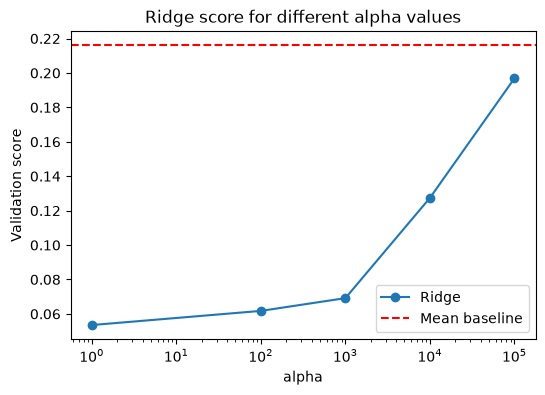

In [23]:
mean_score = sharpe_score(Y_val, mean_pred)

plt.figure(figsize=(6, 4))
plt.plot(alphas, ridge_scores, marker="o", label="Ridge")
plt.axhline(mean_score, color="red", linestyle="--", label="Mean baseline")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Validation score")
plt.title("Ridge score for different alpha values")
plt.legend()
plt.show()

With a small alpha the score is low (0.05). The bigger the alpha, the better the score,
and the best value is 0.197 with alpha = 100000. But even the best Ridge model is still
a bit below the mean baseline (0.216).

A big alpha pushes the coefficients towards 0, so the model uses the features less and
its predictions get closer to the mean of each target. So in this simple form the
features add more noise than signal. This agrees with section 3.4, where today's
return said almost nothing about the future return.

We keep Ridge with alpha = 100000 as our baseline model. Its validation score is 0.197.

In [24]:
best_alpha = 100000
scaler, models = train_baseline(X_train, Y_train, alpha=best_alpha)
val_pred = predict(scaler, models, X_val)

print("Baseline (Ridge, alpha = 100000) validation score:", round(sharpe_score(Y_val, val_pred), 4))

Baseline (Ridge, alpha = 100000) validation score: 0.1969


## 6. Kaggle Submission

We tried to make a late submission with `kaggle_submission.ipynb`. The notebook runs on
Kaggle, but Kaggle answers "Submissions have been disabled for this competition."
(screenshot in `submissions/`). So we cannot get a public or private score.

As the course instructions say, we use a held-out set instead. Our held-out set is the
last 20 % of the training days (393 days), the same validation part as in section 5.
We split by time and not randomly with `train_test_split`. A random split would put
days that are next to each other into both parts, and for a time series the score
would be too optimistic. The score is computed with the competition metric.

In [25]:
print("Held-out score, mean baseline:         ", round(mean_score, 4))
print("Held-out score, Ridge (alpha = 100000):", round(sharpe_score(Y_val, val_pred), 4))

Held-out score, mean baseline:          0.2162
Held-out score, Ridge (alpha = 100000): 0.1969


On the final private leaderboard the winner scored 0.638, the 10th place 0.480 and the
50th place about 0.40. Our Ridge baseline (0.197) is far below them, at about one third
of the winning score. The leaderboard was computed on a later period than our held-out
days, so this comparison is only a rough guide.

## 7. Conclusion

The task is to predict 424 future returns (single instruments and differences of pairs)
from daily prices of LME, JPX, US stocks and Forex. The score only depends on how well
we rank the 424 targets on each day, and on how stable this ranking is over time.

From the EDA we learned that the targets are centred around 0 with long tails, that
their spread grows with the lag, and that targets which share an instrument are
strongly correlated. The prices have long trends, so we turned them into daily log
returns and split the data by time. We also saw that today's return says almost
nothing about the future return.

Our baseline is one Ridge regression per target on 142 daily returns. On the held-out
last 20 % of the days it scores 0.197. A simple prediction of each target's training
mean scores 0.216, so in this simple form the features do not help yet. The best teams
on the leaderboard reached between 0.40 and 0.64.

For Assignment 2 we plan to give the model more history, for example returns over the
last 5 and 20 days and the recent volatility. We also want to use the lagged target
values that the evaluation API gives every day, and to try tree-based models such as
LightGBM. Finally, we want to use time-series cross-validation with several splits
instead of one, so that our score depends less on a single period.